# Single-cell montage of the most confident multi-class predictions

We make an image montage to visually check if there is anything distinct about the cells the multi-class model (`model_all_hearts_final_multiclass`) is most confident about.
Each row is a class (Healthy, ICM, and DCM) and each column is a random single cell chosen from the cells with the highest predicted probability for that class.
We make two montages: one from the most confident cells per class overall, and one with the cells picked evenly across the hearts in each class (the most confident ICM and DCM cells each come from a single heart).

We only use cells the model was not trained on (testing, well holdout, and female heart holdout splits) and that are truly that class.
Each crop is a composite of three channels: nuclei (DNA) in cyan, F-actin in magenta, and ER in yellow.
Every crop is the same size and centered on the cell, so the size of the cells can be compared across classes, and neighboring cells may be visible.
To keep the crops the same size without padding, we only pick cells far enough from the image edge for the crop box to fit inside the image.
Images are illumination corrected (raw image divided by the illumination function, the same as the CellProfiler pipeline) and every crop uses the same contrast per channel, so brightness can be compared across classes.

## Import libraries and helper functions

In [1]:
import os
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from IPython.display import display
from joblib import load

sys.path.append("../utils")
from training_utils import get_X_y_data


def load_corrected_image(cell: pd.Series, channel: str, illum_dir: pathlib.Path) -> np.ndarray:
    """
    Load a raw image for a single cell and apply the illumination correction (divide by the illumination function).

    Args:
        cell (pd.Series): Single-cell row with the image file and path metadata.
        channel (str): Channel to load (e.g., DNA, Actin, or ER).
        illum_dir (pathlib.Path): Directory with the illumination functions for the plate.

    Returns:
        np.ndarray: Illumination corrected image as float.
    """
    raw_image = tifffile.imread(
        pathlib.Path(cell[f"Metadata_Image_PathName_Orig{channel}"])
        / cell[f"Metadata_Image_FileName_Orig{channel}"]
    ).astype(np.float32)
    illum_function = np.load(illum_dir / cell[f"Metadata_Image_FileName_Illum{channel}"])
    return raw_image / illum_function


def crop_centered(image: np.ndarray, center_x: float, center_y: float, crop_size: int) -> np.ndarray:
    """
    Crop a square box centered on a cell (the box must fit inside the image).

    Args:
        image (np.ndarray): Full image.
        center_x (float): X coordinate of the cell center.
        center_y (float): Y coordinate of the cell center.
        crop_size (int): Width and height of the crop in pixels.

    Returns:
        np.ndarray: Crop with shape (crop_size, crop_size).
    """
    x_start = int(round(center_x)) - crop_size // 2
    y_start = int(round(center_y)) - crop_size // 2
    return image[y_start : y_start + crop_size, x_start : x_start + crop_size]


def make_composite(channel_crops: dict, channel_colors: dict, channel_limits: dict) -> np.ndarray:
    """
    Rescale each channel crop with fixed contrast limits and add them together as colors into an RGB composite.

    Args:
        channel_crops (dict): Crop per channel.
        channel_colors (dict): RGB color (0-1) per channel.
        channel_limits (dict): Lower and upper intensity limits per channel (the same for all crops).

    Returns:
        np.ndarray: RGB composite with shape (height, width, 3) and values from 0 to 1.
    """
    composite = np.zeros((*next(iter(channel_crops.values())).shape, 3))
    for channel, crop in channel_crops.items():
        low, high = channel_limits[channel]
        scaled = np.clip((crop - low) / (high - low), 0, 1)
        composite += scaled[..., None] * np.array(channel_colors[channel])
    return np.clip(composite, 0, 1)


def load_selected_images(
    selected_df: pd.DataFrame, channels: list, illum_dir: pathlib.Path, corrected_images: dict
) -> dict:
    """
    Load the illumination corrected images for the selected cells, loading each image only once.

    Args:
        selected_df (pd.DataFrame): Selected cells with the image file and path metadata.
        channels (list): Channels to load.
        illum_dir (pathlib.Path): Directory with the illumination functions for the plate.
        corrected_images (dict): Images that are already loaded (file name to image), updated in place.

    Returns:
        dict: Corrected images per raw image file name.
    """
    for _, cell in selected_df.iterrows():
        for channel in channels:
            file_name = cell[f"Metadata_Image_FileName_Orig{channel}"]
            if file_name not in corrected_images:
                corrected_images[file_name] = load_corrected_image(cell, channel, illum_dir)
    return corrected_images


def make_cell_composites(
    selected_df: pd.DataFrame,
    corrected_images: dict,
    channel_colors: dict,
    channel_limits: dict,
    crop_size: int,
) -> list:
    """
    Crop each selected cell from its images and make an RGB composite.

    Args:
        selected_df (pd.DataFrame): Selected cells with the image file names and cell centers.
        corrected_images (dict): Corrected images per raw image file name.
        channel_colors (dict): RGB color (0-1) per channel.
        channel_limits (dict): Lower and upper intensity limits per channel (the same for all crops).
        crop_size (int): Width and height of the crop in pixels.

    Returns:
        list: RGB composite per selected cell (in the order of selected_df).
    """
    return [
        make_composite(
            channel_crops={
                channel: crop_centered(
                    corrected_images[cell[f"Metadata_Image_FileName_Orig{channel}"]],
                    cell["Metadata_Cells_Location_Center_X"],
                    cell["Metadata_Cells_Location_Center_Y"],
                    crop_size,
                )
                for channel in channel_colors
            },
            channel_colors=channel_colors,
            channel_limits=channel_limits,
        )
        for _, cell in selected_df.iterrows()
    ]


def plot_montage(
    selected_df: pd.DataFrame,
    composites: list,
    class_order: list,
    n_cells_per_class: int,
    channel_colors: dict,
    channel_names: dict,
    title: str,
) -> plt.Figure:
    """
    Plot the composites as a montage with one row per class, labeled with the heart number and probability.

    Args:
        selected_df (pd.DataFrame): Selected cells ordered by class (n_cells_per_class rows per class).
        composites (list): RGB composite per selected cell (in the order of selected_df).
        class_order (list): Order of the classes for the rows.
        n_cells_per_class (int): Number of cells (columns) per class.
        channel_colors (dict): RGB color (0-1) per channel for the legend.
        channel_names (dict): Name per channel for the legend.
        title (str): Title of the montage.

    Returns:
        plt.Figure: Montage figure.
    """
    fig, axes = plt.subplots(
        len(class_order),
        n_cells_per_class,
        figsize=(3.4 * n_cells_per_class + 1.5, 4.1 * len(class_order) + 1.2),
        facecolor="black",
        gridspec_kw={"hspace": 0.18, "wspace": 0.05},
    )
    for ax, composite, (_, cell) in zip(axes.flat, composites, selected_df.iterrows()):
        ax.imshow(composite)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_title(
            f"Heart {cell['Metadata_heart_number']} | p = {cell['Probability']:.2f}",
            color="white",
            fontsize=15,
        )

    for ax, class_name in zip(axes[:, 0], class_order):
        ax.set_ylabel(class_name, color="white", fontsize=22, fontweight="bold", labelpad=12)

    # Channel legend written in the channel colors
    legend_x = np.linspace(0.3, 0.7, len(channel_colors))
    for x, (channel, color) in zip(legend_x, channel_colors.items()):
        fig.text(x, 0.05, channel_names[channel], color=color, fontsize=20, fontweight="bold", ha="center")

    fig.suptitle(title, color="white", fontsize=24, y=0.96)
    return fig

## Set paths and parameters

In [2]:
# Set the plate to process with the PLATE_TO_TRAIN environment variable (defaults to the subtyping plate)
plate_to_process = os.environ.get("PLATE_TO_TRAIN", "CARD-CelIns-CX7_260814100001")

model_path = pathlib.Path(
    f"./models/{plate_to_process}/model_all_hearts_final_multiclass.joblib"
).resolve(strict=True)
encoder_path = pathlib.Path(
    f"./encoder_results/{plate_to_process}/label_encoder_multi-class.joblib"
).resolve(strict=True)
split_dir = pathlib.Path(f"./data_splits/{plate_to_process}").resolve(strict=True)
# Illumination functions for the plate (can be in a subfolder, e.g. hlhs_run/)
illum_dir = next(
    pathlib.Path("../1.illumination_correction/illum_directory")
    .resolve(strict=True)
    .rglob(plate_to_process)
)

# Output dirs for the selected cells and figure
performance_metrics_dir = pathlib.Path(f"./performance_metrics/{plate_to_process}")
performance_metrics_dir.mkdir(parents=True, exist_ok=True)
figure_dir = pathlib.Path(f"./figures/{plate_to_process}")
figure_dir.mkdir(parents=True, exist_ok=True)

# Splits the model was not trained on
split_files = {
    "test": "testing_split.parquet",
    "holdout_well": "holdout_well_split.parquet",
    "holdout_female_hearts": "holdout_female_hearts_split.parquet",
}
# Female heart holdout is only made when the plate has the female hearts
split_files = {
    split_name: file_name
    for split_name, file_name in split_files.items()
    if (split_dir / file_name).exists()
}

# Healthy hearts have no heart failure type
label = "Metadata_heart_failure_type"
healthy_label = "Healthy"

# Order of the classes for the rows (only the classes in the model are kept)
class_order = ["Healthy", "ICM", "DCM", "HLHS"]

# Number of cells per class (columns) and the top cells per class to randomly pick from
n_cells_per_class = 6
n_top_cells = 50
random_seed = 0

# For the heart balanced montage, the top cells per heart to randomly pick from
n_top_cells_per_heart = 10

# Width and height of every crop in pixels (cells are ~340 pixels wide on average)
crop_size = 450
# Width and height of the images in pixels
image_size = 1104

# Composite colors (RGB) per channel
channel_colors = {
    "DNA": (0, 1, 1),  # cyan
    "Actin": (1, 0, 1),  # magenta
    "ER": (1, 1, 0),  # yellow
}
channel_names = {"DNA": "Nuclei", "Actin": "F-actin", "ER": "ER"}

# Percentiles for the contrast limits per channel (computed across all of the selected images)
contrast_percentiles = (1, 99.8)

## Predict the class probabilities for the cells not used in training

The model classes are encoded, so we use the multi-class label encoder to get the class names.

In [3]:
model = load(model_path)
label_encoder = load(encoder_path)
class_names = label_encoder.inverse_transform(model.classes_)
class_order = [class_name for class_name in class_order if class_name in class_names]

cells_df = pd.concat(
    [
        pd.read_parquet(split_dir / file_name).assign(dataset=split_name)
        for split_name, file_name in split_files.items()
    ],
    ignore_index=True,
)
cells_df[label] = cells_df[label].fillna(healthy_label)

X, _ = get_X_y_data(df=cells_df, label=label, shuffle_features=False)
probabilities = model.predict_proba(X[model.feature_names_in_])
for idx, class_name in enumerate(class_names):
    cells_df[f"proba_{class_name}"] = probabilities[:, idx]
cells_df["predicted_label"] = class_names[probabilities.argmax(axis=1)]

display(cells_df.groupby(["dataset", label]).size().unstack(fill_value=0))

Metadata_heart_failure_type,DCM,Healthy,ICM
dataset,,,
holdout_female_hearts,0,588,0
holdout_well,378,466,407
test,481,549,421


## Select random cells from the most confident predictions per class

For each class, we take the top cells by predicted probability for that class (only cells that are truly that class and where the crop box fits in the image) and randomly pick cells from them.

In [4]:
metadata_cols = [
    "dataset",
    "Metadata_Plate",
    "Metadata_Well",
    "Metadata_Site",
    "Metadata_heart_number",
    label,
    "Metadata_Cells_Number_Object_Number",
    "Metadata_Cells_Location_Center_X",
    "Metadata_Cells_Location_Center_Y",
]
image_cols = [
    f"Metadata_Image_{kind}_{source}{channel}"
    for kind in ["PathName", "FileName"]
    for source in ["Orig", "Illum"]
    for channel in channel_colors
]

# Only keep cells where the crop box centered on the cell fits inside the image
half_crop = crop_size // 2
fits_in_image = (
    cells_df["Metadata_Cells_Location_Center_X"].round().between(half_crop, image_size - half_crop)
    & cells_df["Metadata_Cells_Location_Center_Y"].round().between(half_crop, image_size - half_crop)
)

selected_cells = []
for class_name in class_order:
    top_cells = cells_df[fits_in_image & (cells_df[label] == class_name)].nlargest(
        n_top_cells, f"proba_{class_name}"
    )
    selected_cells.append(
        top_cells.sample(n=n_cells_per_class, random_state=random_seed)
        .sort_values(f"proba_{class_name}", ascending=False)
        .assign(Class=class_name, Probability=lambda df: df[f"proba_{class_name}"])
    )
selected_cells_df = pd.concat(selected_cells, ignore_index=True)[
    ["Class", "Probability"] + metadata_cols + image_cols
]

selected_cells_df.drop(columns=image_cols).to_csv(
    performance_metrics_dir / "multiclass_montage_selected_cells.csv", index=False
)
display(selected_cells_df.drop(columns=image_cols))

,Class,Probability,dataset,Metadata_Plate,Metadata_Well,Metadata_Site,Metadata_heart_number,Metadata_heart_failure_type,Metadata_Cells_Number_Object_Number,Metadata_Cells_Location_Center_X,Metadata_Cells_Location_Center_Y
0,Healthy,0.999904,holdout_well,CARD-CelIns-CX7_260814100001,C08,3,7,Healthy,7,461.989809,755.072546
1,Healthy,0.999581,test,CARD-CelIns-CX7_260814100001,B02,10,2,Healthy,3,871.945823,466.127293
2,Healthy,0.999502,holdout_well,CARD-CelIns-CX7_260814100001,C08,0,7,Healthy,4,788.250964,616.226347
3,Healthy,0.998377,holdout_female_hearts,CARD-CelIns-CX7_260814100001,F06,19,32,Healthy,2,537.363015,472.819584
4,Healthy,0.998361,holdout_female_hearts,CARD-CelIns-CX7_260814100001,G11,4,32,Healthy,2,760.572821,768.265084
5,Healthy,0.997669,holdout_well,CARD-CelIns-CX7_260814100001,C08,16,7,Healthy,3,852.604696,866.791847
6,ICM,0.999995,holdout_well,CARD-CelIns-CX7_260814100001,E06,1,44,ICM,3,724.231339,410.143286
7,ICM,0.999804,holdout_well,CARD-CelIns-CX7_260814100001,E06,16,44,ICM,1,780.497953,350.680113
8,ICM,0.999788,holdout_well,CARD-CelIns-CX7_260814100001,E06,1,44,ICM,5,522.964907,604.137391
9,ICM,0.998837,holdout_well,CARD-CelIns-CX7_260814100001,E06,12,44,ICM,7,580.060205,569.045949


## Load the images and set the contrast

The contrast limits per channel are computed across all of the images for the first montage, so the same intensity has the same brightness in every crop.
The heart balanced montage uses the same limits so the two montages can be compared.

In [5]:
corrected_images = load_selected_images(
    selected_df=selected_cells_df,
    channels=list(channel_colors),
    illum_dir=illum_dir,
    corrected_images={},
)

channel_limits = {
    channel: tuple(
        np.percentile(
            np.concatenate(
                [
                    corrected_images[file_name].ravel()
                    for file_name in selected_cells_df[f"Metadata_Image_FileName_Orig{channel}"].unique()
                ]
            ),
            contrast_percentiles,
        )
    )
    for channel in channel_colors
}
display(pd.DataFrame(channel_limits, index=["lower_limit", "upper_limit"]).T)

,lower_limit,upper_limit
DNA,563.330783,7431.402891
Actin,48.278072,1596.901176
ER,90.836258,4138.952554


## Plot the montage of the most confident cells per class

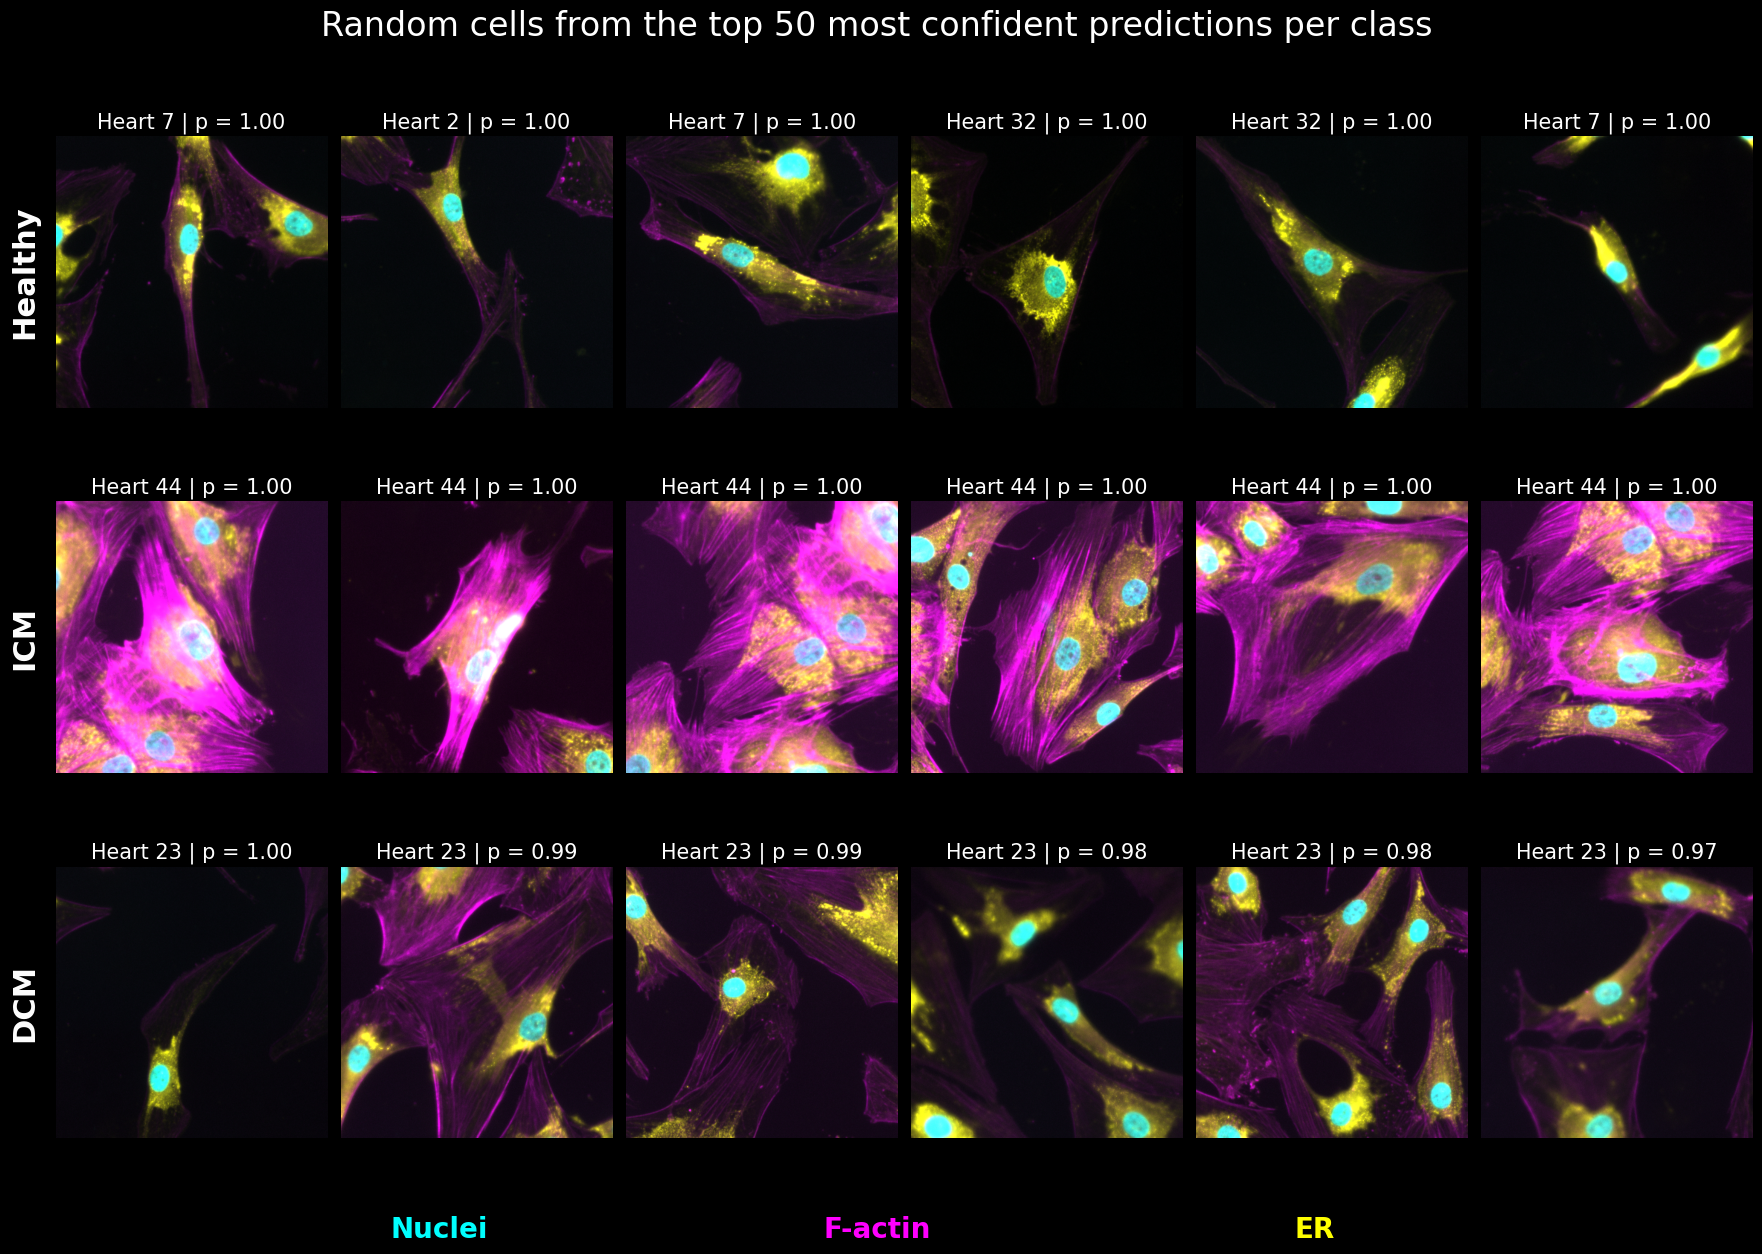

In [6]:
composites = make_cell_composites(
    selected_df=selected_cells_df,
    corrected_images=corrected_images,
    channel_colors=channel_colors,
    channel_limits=channel_limits,
    crop_size=crop_size,
)
fig = plot_montage(
    selected_df=selected_cells_df,
    composites=composites,
    class_order=class_order,
    n_cells_per_class=n_cells_per_class,
    channel_colors=channel_colors,
    channel_names=channel_names,
    title=f"Random cells from the top {n_top_cells} most confident predictions per class",
)
fig.savefig(
    figure_dir / "multiclass_single_cell_montage.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="black",
)
plt.show()

## Select random cells evenly across the hearts per class

The most confident ICM and DCM cells all come from one heart each (hearts 44 and 23), so we also pick the cells evenly across the hearts.
For each heart, we take the top cells by predicted probability for its class and randomly pick the same number of cells per heart (2 per heart for ICM and DCM with 3 hearts each, and 1 per heart for the 6 healthy hearts).

In [7]:
balanced_cells = []
for class_name in class_order:
    class_cells = cells_df[fits_in_image & (cells_df[label] == class_name)]
    hearts = sorted(class_cells["Metadata_heart_number"].unique())
    n_cells_per_heart = n_cells_per_class // len(hearts)
    for heart in hearts:
        top_heart_cells = class_cells[class_cells["Metadata_heart_number"] == heart].nlargest(
            n_top_cells_per_heart, f"proba_{class_name}"
        )
        balanced_cells.append(
            top_heart_cells.sample(n=n_cells_per_heart, random_state=random_seed)
            .sort_values(f"proba_{class_name}", ascending=False)
            .assign(Class=class_name, Probability=lambda df: df[f"proba_{class_name}"])
        )
balanced_cells_df = pd.concat(balanced_cells, ignore_index=True)[
    ["Class", "Probability"] + metadata_cols + image_cols
]

balanced_cells_df.drop(columns=image_cols).to_csv(
    performance_metrics_dir / "multiclass_montage_heart_balanced_selected_cells.csv", index=False
)
display(balanced_cells_df.drop(columns=image_cols))

,Class,Probability,dataset,Metadata_Plate,Metadata_Well,Metadata_Site,Metadata_heart_number,Metadata_heart_failure_type,Metadata_Cells_Number_Object_Number,Metadata_Cells_Location_Center_X,Metadata_Cells_Location_Center_Y
0,Healthy,0.998994,test,CARD-CelIns-CX7_260814100001,B09,16,2,Healthy,4,435.243752,844.422958
1,Healthy,0.999502,holdout_well,CARD-CelIns-CX7_260814100001,C08,0,7,Healthy,4,788.250964,616.226347
2,Healthy,0.999884,holdout_female_hearts,CARD-CelIns-CX7_260814100001,D07,16,32,Healthy,1,849.416439,440.611884
3,Healthy,0.998567,test,CARD-CelIns-CX7_260814100001,F04,10,63,Healthy,3,329.553066,439.976077
4,Healthy,0.965048,holdout_female_hearts,CARD-CelIns-CX7_260814100001,B06,17,64,Healthy,1,547.195660,318.829779
5,Healthy,0.995537,holdout_well,CARD-CelIns-CX7_260814100001,G08,16,66,Healthy,1,641.389943,301.770965
6,ICM,0.996577,test,CARD-CelIns-CX7_260814100001,D04,0,30,ICM,16,321.964308,699.930709
7,ICM,0.989733,test,CARD-CelIns-CX7_260814100001,D04,0,30,ICM,7,690.559168,369.656097
8,ICM,0.999995,holdout_well,CARD-CelIns-CX7_260814100001,E06,1,44,ICM,3,724.231339,410.143286
9,ICM,0.999788,holdout_well,CARD-CelIns-CX7_260814100001,E06,1,44,ICM,5,522.964907,604.137391


## Plot the heart balanced montage

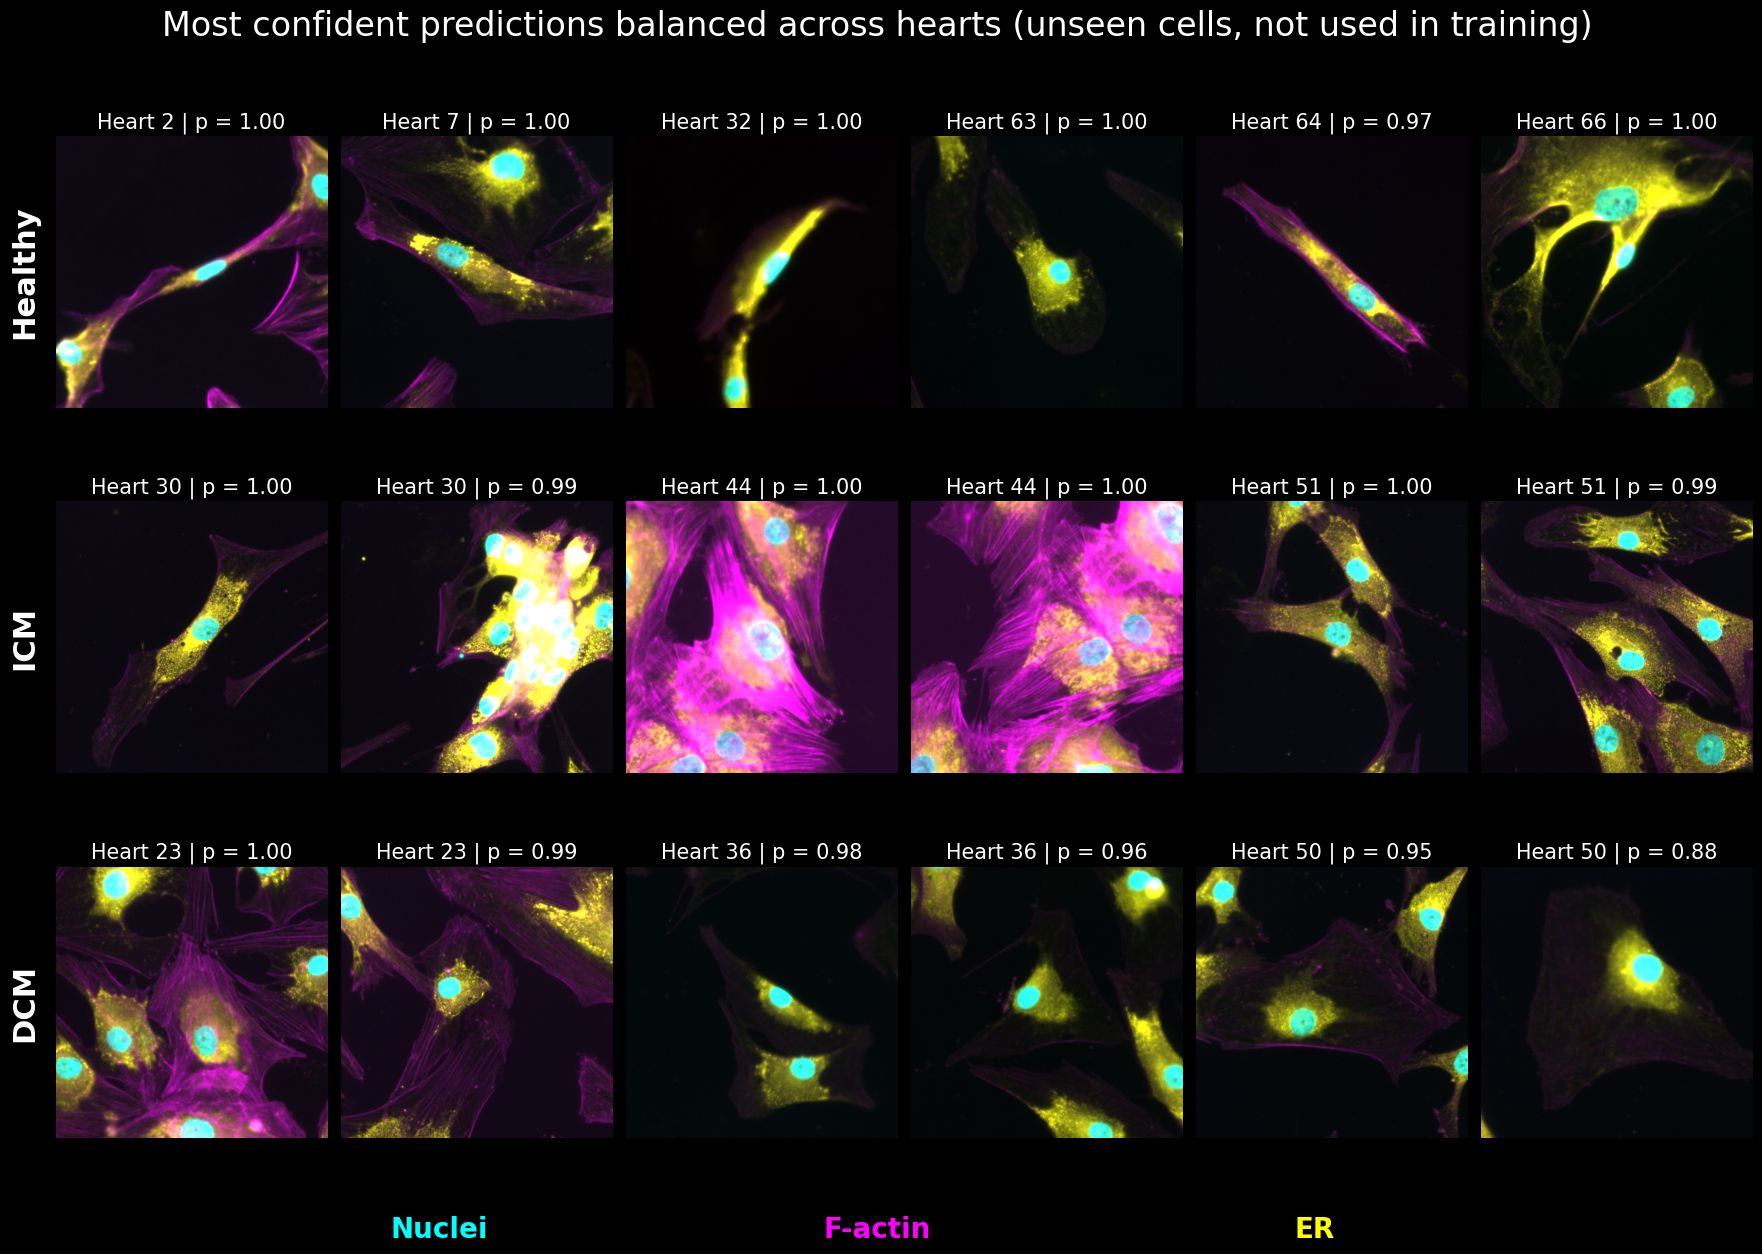

In [8]:
corrected_images = load_selected_images(
    selected_df=balanced_cells_df,
    channels=list(channel_colors),
    illum_dir=illum_dir,
    corrected_images=corrected_images,
)
balanced_composites = make_cell_composites(
    selected_df=balanced_cells_df,
    corrected_images=corrected_images,
    channel_colors=channel_colors,
    channel_limits=channel_limits,
    crop_size=crop_size,
)
fig = plot_montage(
    selected_df=balanced_cells_df,
    composites=balanced_composites,
    class_order=class_order,
    n_cells_per_class=n_cells_per_class,
    channel_colors=channel_colors,
    channel_names=channel_names,
    title="Most confident predictions balanced across hearts (unseen cells, not used in training)",
)
fig.savefig(
    figure_dir / "multiclass_single_cell_montage_heart_balanced.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="black",
)
plt.show()